<a href="https://colab.research.google.com/github/ADRIANVM117/data-science-portfolio/blob/main/scenario-portfolio-lab/notebooks/03_joint_resampling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

El botón abre esta notebook en Google Colab. Allí ejecuta primero la siguiente celda de preparación para obtener el código y los reportes públicos; no descarga datos de mercado ni solicita credenciales.

# 03. Remuestreo conjunto uniforme

Esta notebook construye un primer modelo de referencia de una sesión mediante muestreo con reemplazo de observaciones históricas conjuntas. El objetivo es hacer explícitos sus supuestos, no validarlo como modelo del futuro ni presentar una implementación completa de Fully Flexible Resampling (FFR).

El alcance se limita a la preparación autónoma de las entradas y al remuestreo conjunto uniforme con horizonte $H=1$.

In [1]:
from __future__ import annotations

import hashlib
import json
import site
import sys
from datetime import date
from pathlib import Path

import numpy as np

def find_project_root() -> Path:
    def is_project_root(candidate: Path) -> bool:
        return ((candidate / 'config' / 'universe.csv').is_file()
                and (candidate / 'src' / 'scenario_portfolio_lab').is_dir())

    for origin in (Path.cwd(), *Path.cwd().parents):
        for candidate in (origin, origin / 'scenario-portfolio-lab', origin / 'data-science-portfolio' / 'scenario-portfolio-lab'):
            if is_project_root(candidate):
                return candidate
    raise RuntimeError(
        'Repository files config/universe.csv and src/scenario_portfolio_lab were not found. '
        'Open this notebook from the complete scenario-portfolio-lab repository (or its data-science-portfolio parent). '
        'Do not run it from an exported standalone .ipynb file.'
    )


ROOT = find_project_root()
SRC = ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# MyST/Jupyter kernels may differ from the project virtual environment.
# Reuse already installed local dependencies when this Windows project .venv exists; never install packages here.
LOCAL_SITE_PACKAGES = ROOT / '.venv' / 'Lib' / 'site-packages'
if LOCAL_SITE_PACKAGES.is_dir():
    site.addsitedir(str(LOCAL_SITE_PACKAGES))

try:
    import exchange_calendars as xcals
    import polars as pl
except ModuleNotFoundError as exc:
    raise RuntimeError(
        'Missing project dependencies. Select the project .venv Python 3.13.2 kernel or install requirements.txt '
        'into the active kernel environment before running this notebook.'
    ) from exc

RUN_ROOT = ROOT / 'data' / 'published' / 'cut_2026-10-09_run_2026-10-11_full_window_final'
GOLD_ROOT = RUN_ROOT / 'gold'
PRICE_MATRIX_PATH = GOLD_ROOT / 'adjusted_close_matrix.parquet'
RETURN_MATRIX_PATH = GOLD_ROOT / 'eligible_simple_total_return_matrix.parquet'
RUN_MANIFEST_PATH = RUN_ROOT / 'run_manifest.json'
ELIGIBLE_CATALOG_PATH = RUN_ROOT / 'reports' / 'eligible_universe.csv'

for required in (PRICE_MATRIX_PATH, RETURN_MATRIX_PATH, RUN_MANIFEST_PATH, ELIGIBLE_CATALOG_PATH):
    if not required.is_file():
        raise FileNotFoundError(f'Required final-cut artifact is missing: {required.relative_to(ROOT)}')


## Entradas autónomas y contrato

La notebook reutiliza el mismo corte final, catálogo elegible y convenciones de la notebook 02: 125 instrumentos, 2,205 precios ajustados y 2,204 retornos diarios utilizables. Sólo se retira la primera fila nula prevista de retornos; no se imputan ni se filtran observaciones.

Se validan fechas, orden de símbolos, dominio de `log1p` e integridad de los raw referenciados en el manifiesto. El manifiesto no contiene hashes de referencia para los dos Parquet matriciales; por eso, estas comprobaciones de contenido no equivalen a verificar históricamente esas matrices contra hashes de referencia.

In [2]:
run_manifest = json.loads(RUN_MANIFEST_PATH.read_text(encoding='utf-8'))
approved_period = run_manifest['approved_period']
assert approved_period == {'start': '2018-01-02', 'end': '2026-10-09'}

eligible_catalog = pl.read_csv(ELIGIBLE_CATALOG_PATH).filter(pl.col('universe_status') == 'ELIGIBLE')
eligible_symbols = eligible_catalog['symbol'].to_list()
assert len(eligible_symbols) == 125 and len(set(eligible_symbols)) == 125

raw_hash_checks = []
for symbol, reference in run_manifest['raw'].items():
    raw_path = ROOT / Path(reference['path'].replace('\\', '/'))
    if not raw_path.is_file():
        raise FileNotFoundError(f'Manifest-referenced raw is missing for {symbol}.')
    raw_hash_checks.append(hashlib.sha256(raw_path.read_bytes()).hexdigest() == reference['sha256'])
assert len(raw_hash_checks) == 138 and all(raw_hash_checks)

all_gold_prices = pl.read_parquet(PRICE_MATRIX_PATH)
return_matrix = pl.read_parquet(RETURN_MATRIX_PATH)
assert all_gold_prices.columns[0] == return_matrix.columns[0] == 'session_date'
return_symbols = return_matrix.columns[1:]
assert return_symbols == eligible_symbols
eligible_prices = all_gold_prices.select(['session_date', *return_symbols])
assert eligible_prices.shape == return_matrix.shape == (2205, 126)

start, end = date.fromisoformat(approved_period['start']), date.fromisoformat(approved_period['end'])
expected_dates = [stamp.date() for stamp in xcals.get_calendar('XNYS').sessions if start <= stamp.date() <= end]
for matrix in (eligible_prices, return_matrix):
    matrix_dates = matrix['session_date'].to_list()
    assert matrix_dates == expected_dates
    assert matrix_dates == sorted(matrix_dates) and len(set(matrix_dates)) == len(matrix_dates) == 2205

price_values = eligible_prices.select(pl.exclude('session_date'))
assert all(value == 0 for value in price_values.null_count().row(0))
assert not any(price_values.select(pl.all().is_nan().any()).row(0))
assert not any(price_values.select(pl.all().is_infinite().any()).row(0))
assert not any(price_values.select((pl.all() <= 0).any()).row(0))

first_return_row = return_matrix.slice(0, 1).select(pl.exclude('session_date'))
subsequent_return_rows = return_matrix.slice(1).select(pl.exclude('session_date'))
assert all(value == 1 for value in return_matrix.select(pl.exclude('session_date').null_count()).row(0))
assert all(value == 1 for value in first_return_row.null_count().row(0))
assert all(value == 0 for value in subsequent_return_rows.null_count().row(0))
assert not any(subsequent_return_rows.select(pl.all().is_nan().any()).row(0))
assert not any(subsequent_return_rows.select(pl.all().is_infinite().any()).row(0))

usable_returns = return_matrix.slice(1).select(['session_date', *return_symbols])
assert usable_returns.shape == (2204, 126)
assert usable_returns['session_date'].to_list() == expected_dates[1:]
simple_return_values = usable_returns.select(pl.exclude('session_date')).to_numpy()
domain_failures = np.argwhere(simple_return_values <= -1.0)
if domain_failures.size:
    examples = [{'session_date': str(usable_returns['session_date'][int(i)]), 'symbol': return_symbols[int(j)], 'simple_return': float(simple_return_values[i, j])} for i, j in domain_failures[:10]]
    raise ValueError(f'Log-return domain failure (r <= -1); first locations: {examples}')
log_return_values = np.log1p(simple_return_values)
if not np.isfinite(log_return_values).all():
    raise ValueError('Log-return transformation produced a non-finite value.')

historical_dates = np.asarray(usable_returns['session_date'].to_list())
T, N = log_return_values.shape
assert (T, N) == (2204, 125)
historical_probabilities = np.full(T, 1.0 / T, dtype=float)
assert np.isfinite(historical_probabilities).all() and (historical_probabilities > 0.0).all()
assert np.isclose(float(historical_probabilities.sum()), 1.0, rtol=0.0, atol=1e-12)

input_validation_summary = pl.DataFrame({
    'check': ['Approved period', 'Eligible symbols', 'Price matrix', 'Usable simple-return matrix', 'Log-return matrix', 'Manifest-referenced raw hashes', 'Matrix reference hashes'],
    'result': ['2018-01-02 to 2026-10-09', '125 exact symbols, explicit order', '2,205 rows × (date + 125); positive, finite, no nulls', '2,204 rows × (date + 125); first null row removed only', '2,204 rows × 125; finite and log1p domain valid', '138/138 verified against manifest references', 'Not available in run_manifest; no new hash is treated as prior evidence'],
})
input_validation_summary


check,result
str,str
"""Approved period""","""2018-01-02 to 2026-10-09"""
"""Eligible symbols""","""125 exact symbols, explicit or…"
"""Price matrix""","""2,205 rows × (date + 125); pos…"
"""Usable simple-return matrix""","""2,204 rows × (date + 125); fir…"
"""Log-return matrix""","""2,204 rows × 125; finite and l…"
"""Manifest-referenced raw hashes""","""138/138 verified against manif…"
"""Matrix reference hashes""","""Not available in run_manifest;…"


## 1. Remuestreo conjunto uniforme a una sesión

Con probabilidades históricas uniformes, se define:

$$I_s \sim \mathrm{Categorical}(p_1,\ldots,p_T), \qquad \ell_s^*=\ell_{I_s}, \qquad r_s^*=\mathrm{expm1}(\ell_s^*).$$

Cada índice selecciona una sesión completa y, con ella, los 125 retornos simultáneos. La masa histórica $p_t$ pertenece a la distribución de origen; la frecuencia observada de un índice en una simulación finita puede diferir de ella. Cada realización generada recibe además un peso Monte Carlo de $1/S$.

La fecha seleccionada identifica la observación histórica de origen; no es una fecha futura.

In [3]:
HORIZON_SESSIONS = 1
SIMULATION_COUNT = 10_000
RNG_SEED = 20_261_009
RNG_NAME = 'NumPy Generator(PCG64)'
RECOVERY_ABSOLUTE_TOLERANCE, RECOVERY_RELATIVE_TOLERANCE = 1e-12, 1e-10

rng = np.random.Generator(np.random.PCG64(RNG_SEED))
selected_indices = rng.choice(T, size=SIMULATION_COUNT, replace=True, p=historical_probabilities)
selected_source_dates = historical_dates[selected_indices]
selected_log_returns = log_return_values[selected_indices, :]
selected_simple_returns = np.expm1(selected_log_returns)
selected_original_simple_returns = simple_return_values[selected_indices, :]
monte_carlo_weights = np.full(SIMULATION_COUNT, 1.0 / SIMULATION_COUNT, dtype=float)
selection_frequencies = np.bincount(selected_indices, minlength=T)

EXPOSURE_EXAMPLES = ('SPY', 'TLT', 'GLD')
missing_examples = [symbol for symbol in EXPOSURE_EXAMPLES if symbol not in return_symbols]
if missing_examples:
    raise RuntimeError(f'Los ejemplos no están en el universo elegible; no se hizo sustitución: {missing_examples}')
example_indices = [return_symbols.index(symbol) for symbol in EXPOSURE_EXAMPLES]

replayed_rng = np.random.Generator(np.random.PCG64(RNG_SEED))
replayed_indices = replayed_rng.choice(T, size=SIMULATION_COUNT, replace=True, p=historical_probabilities)

resampling_checks = {
    'Exactamente S índices enteros en el rango válido': selected_indices.shape == (SIMULATION_COUNT,) and np.issubdtype(selected_indices.dtype, np.integer) and bool(((selected_indices >= 0) & (selected_indices < T)).all()),
    'Dimensiones S × 125': selected_log_returns.shape == selected_simple_returns.shape == (SIMULATION_COUNT, N),
    'Orden explícito de símbolos conservado': tuple(return_symbols) == tuple(eligible_symbols) and len(return_symbols) == N,
    'Cada vector logarítmico coincide con su fila histórica de origen': bool(np.array_equal(selected_log_returns, log_return_values[selected_indices, :])),
    'Fechas de origen alineadas con los índices': bool(np.array_equal(selected_source_dates, historical_dates[selected_indices])),
    'Retornos simples recuperados coinciden con los originales': bool(np.allclose(selected_simple_returns, selected_original_simple_returns, rtol=RECOVERY_RELATIVE_TOLERANCE, atol=RECOVERY_ABSOLUTE_TOLERANCE)),
    'Retornos seleccionados finitos y dentro del dominio': bool(np.isfinite(selected_log_returns).all() and np.isfinite(selected_simple_returns).all() and (selected_simple_returns > -1.0).all()),
    'Frecuencias de selección suman S': selection_frequencies.shape == (T,) and int(selection_frequencies.sum()) == SIMULATION_COUNT,
    'Pesos Monte Carlo positivos y con suma uno': bool(np.isfinite(monte_carlo_weights).all() and (monte_carlo_weights > 0.0).all() and np.isclose(float(monte_carlo_weights.sum()), 1.0, rtol=0.0, atol=1e-12)),
    'Misma configuración reproduce los mismos índices': bool(np.array_equal(selected_indices, replayed_indices)),
}
if not all(resampling_checks.values()):
    failed_checks = [name for name, passed in resampling_checks.items() if not passed]
    raise AssertionError(f'La validación de remuestreo conjunto falló sin alterar los datos: {failed_checks}')

simulation_preview = pl.DataFrame({
    'simulation_id': np.arange(5, dtype=int),
    'historical_index': selected_indices[:5],
    'source_date': selected_source_dates[:5],
    **{f'{symbol}_simple_return': selected_simple_returns[:5, index] for symbol, index in zip(EXPOSURE_EXAMPLES, example_indices)},
})
resampling_configuration = pl.DataFrame({
    'item': ['Historical observations (T)', 'Instruments (N)', 'Simulations (S)', 'Horizon (H)', 'Seed', 'Generator', 'Historical probability', 'Monte Carlo weight', 'Distinct historical observations selected'],
    'value': [str(T), str(N), str(SIMULATION_COUNT), '1 session', str(RNG_SEED), RNG_NAME, f'1/{T} = {historical_probabilities[0]:.18f}', f'1/{SIMULATION_COUNT} = {monte_carlo_weights[0]:.10f}', str(int((selection_frequencies > 0).sum()))],
})
resampling_check_summary = pl.DataFrame({'check': list(resampling_checks), 'result': ['PASS' if passed else 'FAIL' for passed in resampling_checks.values()]})

resampling_configuration, simulation_preview, resampling_check_summary


(shape: (9, 2)
 ┌─────────────────────────────────┬───────────────────────────────┐
 │ item                            ┆ value                         │
 │ ---                             ┆ ---                           │
 │ str                             ┆ str                           │
 ╞═════════════════════════════════╪═══════════════════════════════╡
 │ Historical observations (T)     ┆ 2204                          │
 │ Instruments (N)                 ┆ 125                           │
 │ Simulations (S)                 ┆ 10000                         │
 │ Horizon (H)                     ┆ 1 session                     │
 │ Seed                            ┆ 20261009                      │
 │ Generator                       ┆ NumPy Generator(PCG64)        │
 │ Historical probability          ┆ 1/2204 = 0.000453720508166969 │
 │ Monte Carlo weight              ┆ 1/10000 = 0.0001000000        │
 │ Distinct historical observatio… ┆ 2183                          │
 └─────────────────

## Interpretación y límites

Seleccionar vectores completos conserva la estructura conjunta de la distribución empírica de origen. Una simulación finita, sin embargo, presenta error Monte Carlo. Usarla como distribución futura supone que la historia observada, con pesos uniformes, es representativa. Este modelo no condiciona en el estado actual ni favorece observaciones recientes.

Las realizaciones se sortean independientemente: esa es una decisión del simulador, no una propiedad demostrada de los datos. Como $H=1$, todavía no se modela dependencia entre sesiones de una trayectoria. El soporte de los vectores diarios queda limitado a observaciones históricas; aumentar $S$ reduce error Monte Carlo, pero no aporta información histórica nueva ni resuelve errores del modelo.

No se implementan aún trayectorias multisesión, ponderación temporal, estados, FFR, Entropy Pooling, carteras, VaR/CVaR, optimización ni backtest. Las filas mostradas son realizaciones independientes de una sesión, no una trayectoria temporal.

## 2. Remuestreo conjunto independiente a cinco sesiones

Para $I_{s,h}\sim\mathrm{Categorical}(p_1,\ldots,p_T)$, con sorteos independientes entre realizaciones y pasos, se usa $\ell^*_{s,h}=\ell_{I_{s,h}}$ y $R^*_{s,h}=\mathrm{expm1}(\sum_{u=1}^{h}\ell^*_{s,u})$. Cada paso conserva una fila histórica completa de 125 instrumentos. Los cinco pasos son sesiones futuras abstractas; sus fechas sólo identifican procedencia histórica y no necesitan ser consecutivas ni ordenadas.

In [4]:
MULTI_SESSION_SIMULATION_COUNT, MULTI_SESSION_HORIZON = 10_000, 5
MULTI_SESSION_SEED, MULTI_SESSION_RNG_NAME = 20_261_009, 'NumPy Generator(PCG64)'
MULTI_SESSION_ABSOLUTE_TOLERANCE, MULTI_SESSION_RELATIVE_TOLERANCE = 1e-12, 1e-10
multi_session_rng = np.random.Generator(np.random.PCG64(MULTI_SESSION_SEED))
multi_session_indices = multi_session_rng.choice(T, size=(MULTI_SESSION_SIMULATION_COUNT, MULTI_SESSION_HORIZON), replace=True, p=historical_probabilities)
multi_session_source_dates = historical_dates[multi_session_indices]
multi_session_daily_log_returns = log_return_values[multi_session_indices, :]
multi_session_daily_simple_returns = np.expm1(multi_session_daily_log_returns)
multi_session_cumulative_log_returns = np.cumsum(multi_session_daily_log_returns, axis=1)
multi_session_cumulative_simple_returns = np.expm1(multi_session_cumulative_log_returns)
multi_session_terminal_simple_returns = multi_session_cumulative_simple_returns[:, -1, :]
multi_session_monte_carlo_weights = np.full(MULTI_SESSION_SIMULATION_COUNT, 1.0 / MULTI_SESSION_SIMULATION_COUNT)
multi_session_selection_frequencies = np.bincount(multi_session_indices.ravel(), minlength=T)
multi_session_replay_rng = np.random.Generator(np.random.PCG64(MULTI_SESSION_SEED))
multi_session_replayed_indices = multi_session_replay_rng.choice(T, size=(MULTI_SESSION_SIMULATION_COUNT, MULTI_SESSION_HORIZON), replace=True, p=historical_probabilities)
multi_session_product = np.cumprod(1.0 + multi_session_daily_simple_returns, axis=1) - 1.0
multi_session_abs_error = float(np.abs(multi_session_cumulative_simple_returns - multi_session_product).max())
multi_session_checks = {
    'Índices S × H enteros y válidos': multi_session_indices.shape == (10_000, 5) and np.issubdtype(multi_session_indices.dtype, np.integer) and bool(((multi_session_indices >= 0) & (multi_session_indices < T)).all()),
    'Vectores diarios coinciden con filas históricas': bool(np.array_equal(multi_session_daily_log_returns, log_return_values[multi_session_indices, :])),
    'Fechas alineadas con índices': bool(np.array_equal(multi_session_source_dates, historical_dates[multi_session_indices])),
    'Dimensiones S × H × 125 y finitud': multi_session_daily_log_returns.shape == (10_000, 5, N) and np.isfinite(multi_session_daily_log_returns).all() and np.isfinite(multi_session_cumulative_simple_returns).all(),
    'Dominio de retornos diarios y acumulados': bool((multi_session_daily_simple_returns > -1.0).all() and (multi_session_cumulative_simple_returns > -1.0).all()),
    'Reproducibilidad de índices': bool(np.array_equal(multi_session_indices, multi_session_replayed_indices)),
    'Frecuencias suman S × H': int(multi_session_selection_frequencies.sum()) == 50_000,
    'Composición logarítmica coincide con producto simple': multi_session_abs_error <= MULTI_SESSION_ABSOLUTE_TOLERANCE,
    'Primer acumulado coincide con retorno diario': bool(np.allclose(multi_session_cumulative_simple_returns[:, 0, :], multi_session_daily_simple_returns[:, 0, :], rtol=MULTI_SESSION_RELATIVE_TOLERANCE, atol=MULTI_SESSION_ABSOLUTE_TOLERANCE)),
    'Terminal coincide con último acumulado': bool(np.array_equal(multi_session_terminal_simple_returns, multi_session_cumulative_simple_returns[:, -1, :])),
    'Pesos Monte Carlo válidos': bool((multi_session_monte_carlo_weights > 0).all() and np.isclose(multi_session_monte_carlo_weights.sum(), 1.0, atol=1e-12)),
}
if not all(multi_session_checks.values()): raise AssertionError([key for key, value in multi_session_checks.items() if not value])
first_path_preview = pl.DataFrame({'future_step': np.arange(1, 6), 'source_date': multi_session_source_dates[0], **{f'{symbol}_daily_simple_return': multi_session_daily_simple_returns[0, :, index] for symbol, index in zip(EXPOSURE_EXAMPLES, example_indices)}, **{f'{symbol}_cumulative_simple_return': multi_session_cumulative_simple_returns[0, :, index] for symbol, index in zip(EXPOSURE_EXAMPLES, example_indices)}})
multi_session_configuration = pl.DataFrame({'item': ['T', 'N', 'S', 'H', 'Seed', 'Generator', 'Distinct historical observations'], 'value': [str(T), str(N), '10000', '5 abstract sessions', str(MULTI_SESSION_SEED), MULTI_SESSION_RNG_NAME, str(int((multi_session_selection_frequencies > 0).sum()))]})
multi_session_check_summary = pl.DataFrame({'check': list(multi_session_checks), 'result': ['PASS'] * len(multi_session_checks)})
multi_session_configuration, first_path_preview, multi_session_check_summary


(shape: (7, 2)
 ┌─────────────────────────────────┬────────────────────────┐
 │ item                            ┆ value                  │
 │ ---                             ┆ ---                    │
 │ str                             ┆ str                    │
 ╞═════════════════════════════════╪════════════════════════╡
 │ T                               ┆ 2204                   │
 │ N                               ┆ 125                    │
 │ S                               ┆ 10000                  │
 │ H                               ┆ 5 abstract sessions    │
 │ Seed                            ┆ 20261009               │
 │ Generator                       ┆ NumPy Generator(PCG64) │
 │ Distinct historical observatio… ┆ 2204                   │
 └─────────────────────────────────┴────────────────────────┘,
 shape: (5, 8)
 ┌────────────┬────────────┬────────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
 │ future_ste ┆ source_dat ┆ SPY_daily_ ┆ TLT_daily ┆ GLD_dai

Cada paso conserva una observación transversal completa, pero la combinación puede generar recorridos no observados históricamente. El modelo no conserva secuencias, persistencia de volatilidad ni transiciones entre sesiones; las 10,000 trayectorias no son 10,000 observaciones nuevas de mercado. H=5 es una elección pedagógica, no una recomendación ni un parámetro atribuido a un libro.

# 3. Lectura de la distribución simulada y sus supuestos

Se examinan los terminales existentes H=1 y H=5, sin generar sorteos nuevos. Con $\mu=\sum_t p_t\ell_t$ y $\Sigma=\sum_t p_t(\ell_t-\mu)(\ell_t-\mu)^\top$, la independencia impuesta por el modelo da exactamente $E[L_H]=H\mu$, $\mathrm{Cov}(L_H)=H\Sigma$ y $\mathrm{SD}(L_H)=\sqrt{H}\sigma$. Son identidades del modelo en log-retornos, no leyes demostradas del mercado ni reglas para retornos simples.

La referencia para la media simulada es $\mathrm{SE}_{MC}(\overline L_H)=\sqrt{H\sigma^2/S}$. Mide la incertidumbre Monte Carlo condicional a historia y modelo fijos; no incluye incertidumbre histórica ni error de modelo.

In [5]:
READING_ABSOLUTE_TOLERANCE, READING_RELATIVE_TOLERANCE, READING_QUANTILE_CDF_TOLERANCE = 1e-14, 1e-11, 1e-12
historical_log_mean = np.sum(historical_probabilities[:, None] * log_return_values, axis=0)
historical_log_centered = log_return_values - historical_log_mean
historical_log_covariance = (historical_log_centered * historical_probabilities[:, None]).T @ historical_log_centered
historical_log_variance, historical_log_std = np.diag(historical_log_covariance), np.sqrt(np.diag(historical_log_covariance))
independent_mean, independent_covariance = np.mean(log_return_values, axis=0), np.cov(log_return_values, rowvar=False, bias=True)
horizon_log = {1: selected_log_returns, 5: multi_session_cumulative_log_returns[:, -1, :]}
horizon_simple = {1: selected_simple_returns, 5: multi_session_terminal_simple_returns}
horizon_weights = {1: monte_carlo_weights, 5: multi_session_monte_carlo_weights}
quantile_levels, quantile_labels = np.array([.05, .50, .95]), ['q05', 'q50', 'q95']
terminal_rows, comparison_rows, quantile_checks = [], [], []
for horizon in (1, 5):
    logs, simple, weights = horizon_log[horizon], horizon_simple[horizon], horizon_weights[horizon]
    log_mean = np.sum(weights[:, None] * logs, axis=0); log_std = np.sqrt(np.sum(weights[:, None] * (logs - log_mean)**2, axis=0))
    simple_mean = np.sum(weights[:, None] * simple, axis=0); simple_std = np.sqrt(np.sum(weights[:, None] * (simple - simple_mean)**2, axis=0))
    ordered = np.sort(simple, axis=0); q = ordered[np.ceil(quantile_levels * SIMULATION_COUNT).astype(int) - 1]
    quantile_checks += [bool(np.all(np.diff(q, axis=0) >= 0)), bool(all(np.all(np.any(ordered == q[level][None, :], axis=0)) for level in range(3)))]
    expected_mean, expected_std = horizon * historical_log_mean, np.sqrt(horizon) * historical_log_std
    se = np.sqrt(horizon * historical_log_variance / SIMULATION_COUNT); standardized = np.full(N, np.nan); positive = se > 0; standardized[positive] = (log_mean[positive] - expected_mean[positive]) / se[positive]
    for index, symbol in enumerate(return_symbols):
        terminal_rows.append({'horizon_sessions': horizon, 'symbol': symbol, 'observations': SIMULATION_COUNT, 'simple_mean': float(simple_mean[index]), 'simple_std': float(simple_std[index]), **{label: float(q[level, index]) for level, label in enumerate(quantile_labels)}})
        comparison_rows.append({'horizon_sessions': horizon, 'symbol': symbol, 'simulated_log_mean': float(log_mean[index]), 'model_log_mean': float(expected_mean[index]), 'mean_difference': float(log_mean[index]-expected_mean[index]), 'monte_carlo_mean_se': float(se[index]), 'standardized_mean_difference': None if not positive[index] else float(standardized[index]), 'simulated_log_std': float(log_std[index]), 'model_log_std_sqrt_h': float(expected_std[index]), 'std_difference': float(log_std[index]-expected_std[index])})
terminal_simple_statistics = pl.DataFrame(terminal_rows).sort(['horizon_sessions', 'symbol'])
log_monte_carlo_comparison = pl.DataFrame(comparison_rows).sort(['horizon_sessions', 'symbol'])
moment_mean_error, moment_covariance_error = float(np.abs(historical_log_mean-independent_mean).max()), float(np.abs(historical_log_covariance-independent_covariance).max())
reading_checks = {
    'Momentos históricos concilian con cálculo independiente': moment_mean_error <= READING_ABSOLUTE_TOLERANCE and moment_covariance_error <= READING_ABSOLUTE_TOLERANCE,
    'Resúmenes usan S realizaciones y 125 instrumentos': all(values.shape == (SIMULATION_COUNT, N) for values in horizon_simple.values()),
    'Cuantiles ordenados y valores observados': all(quantile_checks),
    'Terminales H=1 conservan la simulación existente': bool(np.array_equal(horizon_log[1], selected_log_returns) and np.array_equal(horizon_simple[1], selected_simple_returns)),
    'Terminales H=5 conservan el último acumulado existente': bool(np.array_equal(horizon_log[5], multi_session_cumulative_log_returns[:, -1, :]) and np.array_equal(horizon_simple[5], multi_session_terminal_simple_returns)),
    'Índices, probabilidades y pesos permanecen alineados': bool(np.array_equal(selected_log_returns, log_return_values[selected_indices]) and np.array_equal(multi_session_daily_log_returns, log_return_values[multi_session_indices]) and np.array_equal(historical_probabilities, np.full(T, 1/T))),
}
if not all(reading_checks.values()): raise AssertionError([key for key, value in reading_checks.items() if not value])
example_order = {symbol: index for index, symbol in enumerate(EXPOSURE_EXAMPLES)}
example_terminal_statistics = terminal_simple_statistics.filter(pl.col('symbol').is_in(EXPOSURE_EXAMPLES)).with_columns(pl.col('symbol').replace_strict(example_order).alias('_order')).sort(['horizon_sessions', '_order']).drop('_order')
example_log_monte_carlo_comparison = log_monte_carlo_comparison.filter(pl.col('symbol').is_in(EXPOSURE_EXAMPLES)).with_columns(pl.col('symbol').replace_strict(example_order).alias('_order')).sort(['horizon_sessions', '_order']).drop('_order')
reading_error_summary = pl.DataFrame({'identity': ['Media histórica', 'Covarianza histórica'], 'max_absolute_error': [moment_mean_error, moment_covariance_error], 'result': ['PASS', 'PASS']})
reading_check_summary = pl.DataFrame({'check': list(reading_checks), 'result': ['PASS'] * len(reading_checks)})
from IPython.display import display
display(example_terminal_statistics); display(example_log_monte_carlo_comparison)
reading_error_summary, reading_check_summary


horizon_sessions,symbol,observations,simple_mean,simple_std,q05,q50,q95
i64,str,i64,f64,f64,f64,f64,f64
1,"""SPY""",10000,0.000625,0.012236,-0.017364,0.000761,0.016143
1,"""TLT""",10000,-0.000062,0.009575,-0.014956,0.000072,0.014956
1,"""GLD""",10000,0.000869,0.010884,-0.016166,0.000804,0.017469
5,"""SPY""",10000,0.002833,0.026819,-0.040278,0.003576,0.042485
5,"""TLT""",10000,-0.000441,0.021554,-0.034842,-0.000389,0.034595
5,"""GLD""",10000,0.003029,0.024276,-0.03652,0.003622,0.041337


horizon_sessions,symbol,simulated_log_mean,model_log_mean,mean_difference,monte_carlo_mean_se,standardized_mean_difference,simulated_log_std,model_log_std_sqrt_h,std_difference
i64,str,f64,f64,f64,f64,f64,f64,f64,f64
1,"""SPY""",0.00055,0.000543,0.000007,0.00012,0.054956,0.012289,0.011978,0.000311
1,"""TLT""",-0.000108,-0.0001,-0.000008,0.000096,-0.086358,0.009577,0.009638,-0.000061
1,"""GLD""",0.00081,0.000509,0.0003,0.000108,2.782986,0.010905,0.010789,0.000116
5,"""SPY""",0.002471,0.002716,-0.000245,0.000268,-0.91441,0.026821,0.026783,0.000038
5,"""TLT""",-0.000674,-0.0005,-0.000174,0.000216,-0.807885,0.021569,0.021552,0.000017
5,"""GLD""",0.00273,0.002547,0.000183,0.000241,0.758648,0.024329,0.024126,0.000203


(shape: (2, 3)
 ┌──────────────────────┬────────────────────┬────────┐
 │ identity             ┆ max_absolute_error ┆ result │
 │ ---                  ┆ ---                ┆ ---    │
 │ str                  ┆ f64                ┆ str    │
 ╞══════════════════════╪════════════════════╪════════╡
 │ Media histórica      ┆ 3.2526e-19         ┆ PASS   │
 │ Covarianza histórica ┆ 3.4694e-18         ┆ PASS   │
 └──────────────────────┴────────────────────┴────────┘,
 shape: (6, 2)
 ┌─────────────────────────────────┬────────┐
 │ check                           ┆ result │
 │ ---                             ┆ ---    │
 │ str                             ┆ str    │
 ╞═════════════════════════════════╪════════╡
 │ Momentos históricos concilian … ┆ PASS   │
 │ Resúmenes usan S realizaciones… ┆ PASS   │
 │ Cuantiles ordenados y valores … ┆ PASS   │
 │ Terminales H=1 conservan la si… ┆ PASS   │
 │ Terminales H=5 conservan el úl… ┆ PASS   │
 │ Índices, probabilidades y peso… ┆ PASS   │
 └─────────────

## Visualizaciones acotadas

Los histogramas muestran frecuencias relativas H=1 y H=5 con intervalo compartido por instrumento y todos los extremos. Las trayectorias son los identificadores fijos 0–4, con paso 0 igual a cero; no son intervalos de confianza ni recorridos representativos.

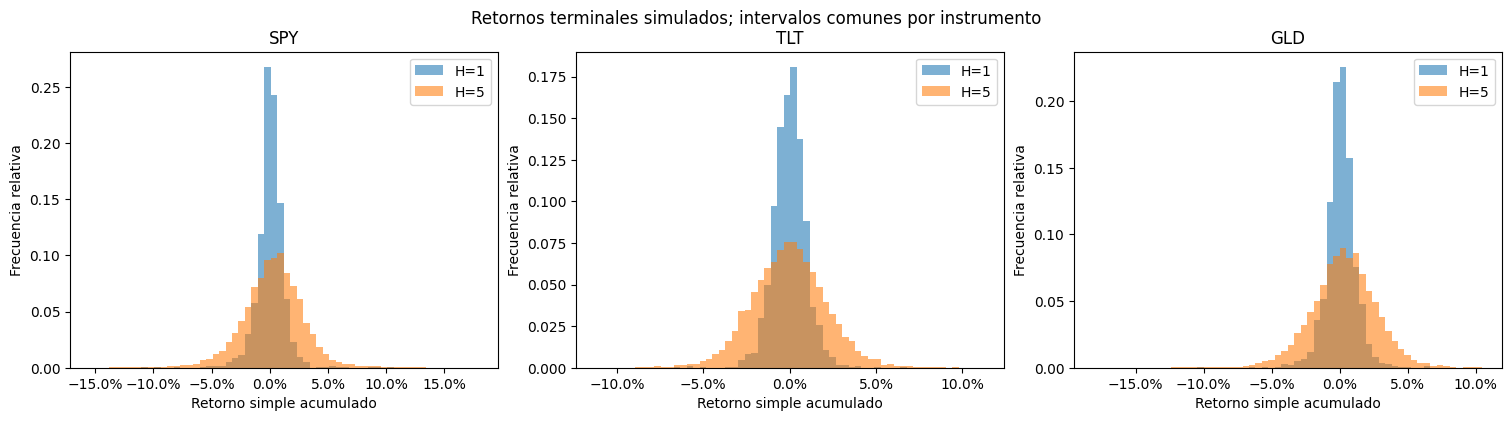

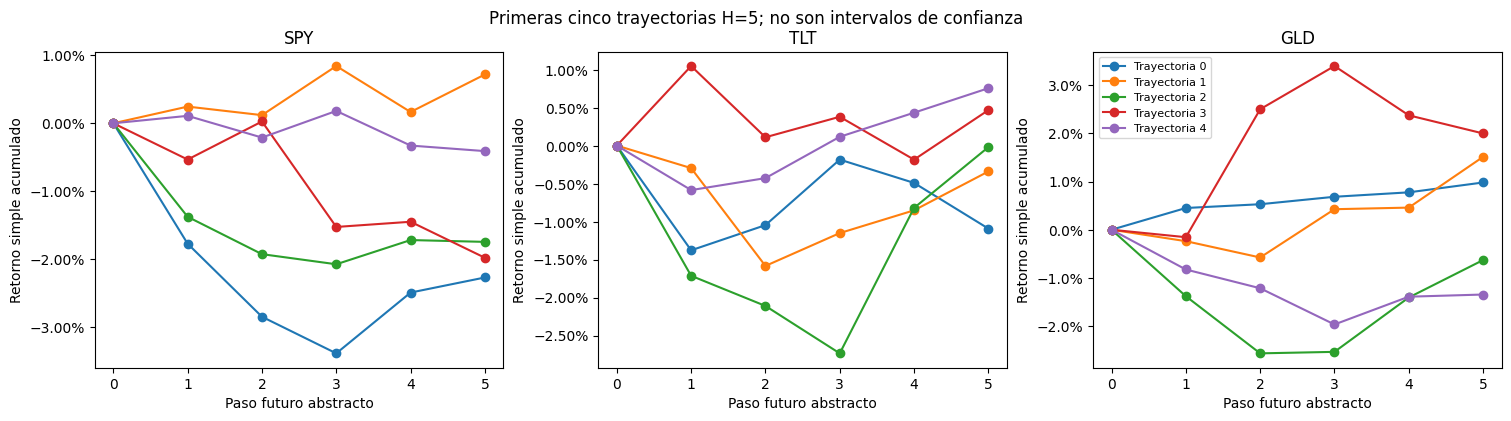

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
PLOT_PATH_IDS = np.arange(5, dtype=int); assert np.array_equal(PLOT_PATH_IDS, np.arange(5))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), constrained_layout=True)
for axis, symbol, index in zip(axes, EXPOSURE_EXAMPLES, example_indices):
    h1, h5 = horizon_simple[1][:, index], horizon_simple[5][:, index]; bins = np.linspace(min(h1.min(), h5.min()), max(h1.max(), h5.max()), 61); weights = np.full(SIMULATION_COUNT, 1/SIMULATION_COUNT)
    axis.hist(h1, bins=bins, weights=weights, alpha=.58, label='H=1'); axis.hist(h5, bins=bins, weights=weights, alpha=.58, label='H=5'); axis.set_title(symbol); axis.set_xlabel('Retorno simple acumulado'); axis.set_ylabel('Frecuencia relativa'); axis.xaxis.set_major_formatter(PercentFormatter(1)); axis.legend()
fig.suptitle('Retornos terminales simulados; intervalos comunes por instrumento', y=1.04); plt.show()
colors = plt.rcParams['axes.prop_cycle'].by_key()['color'][:5]; steps = np.arange(6)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharex=True, constrained_layout=True)
for axis, symbol, index in zip(axes, EXPOSURE_EXAMPLES, example_indices):
    for path_id, color in zip(PLOT_PATH_IDS, colors): axis.plot(steps, np.r_[0.0, multi_session_cumulative_simple_returns[path_id, :, index]], marker='o', color=color, label=f'Trayectoria {path_id}')
    axis.set_title(symbol); axis.set_xlabel('Paso futuro abstracto'); axis.set_ylabel('Retorno simple acumulado'); axis.yaxis.set_major_formatter(PercentFormatter(1)); axis.set_xticks(steps)
axes[-1].legend(fontsize=8); fig.suptitle('Primeras cinco trayectorias H=5; no son intervalos de confianza', y=1.04); plt.show()


## Interpretación y límites

Las tablas comparan diferencias Monte Carlo con referencias exactas del modelo en log-retornos; no son controles PASS/FAIL de capacidad predictiva. En esta ejecución, la desviación estándar simple terminal pasó de 0.012236 a 0.026819 para SPY, de 0.009575 a 0.021554 para TLT y de 0.010884 a 0.024276 para GLD al pasar de H=1 a H=5. Las desviaciones estándar logarítmicas H=5 simuladas/referencia $\sqrt{H}$ fueron 0.026821/0.026783 para SPY, 0.021569/0.021552 para TLT y 0.024329/0.024126 para GLD.

También aparecen diferencias entre medias y medianas simples: para SPY, H=5 produjo media 0.002833 y mediana 0.003576; para TLT, -0.000441 y -0.000389; para GLD, 0.003029 y 0.003622. `expm1` de una media logarítmica no equivale, en general, a la media de retornos simples. La mayor dispersión terminal al aumentar el horizonte procede de la independencia impuesta; no valida dependencia temporal ni oportunidades de inversión.

No se implementan ponderación temporal, estados, FFR, Entropy Pooling, carteras, optimización ni backtest.

# 4. Ponderación temporal de las observaciones históricas

**Nota de procedencia.** El bloque H=5 fue restaurado con `NumPy Generator(PCG64)`, semilla `20261009`, $S=10{,}000$ y $H=5$, y la versión actual se ejecutó y validó. No hay una referencia anterior verificable disponible en esta notebook, por lo que no se afirma identidad exacta con una implementación previa.

Este bloque cambia la distribución histórica de origen mediante pesos de recencia. No modela dependencia temporal entre pasos y no implementa FFR. No genera nuevas simulaciones.

## Pesos exponenciales por sesiones observadas

Con filas ordenadas $t=1,\ldots,T$, la edad es $a_t=T-t$: se mide en sesiones observadas, no en días calendario, y la última observación tiene edad cero. Se define

$$p_t^{exp}=\frac{\exp[-\log(2)a_t/\tau]}{\sum_{u=1}^T\exp[-\log(2)a_u/\tau]}.$$

Se fija $T=2{,}204$ y $\tau=T/2=1{,}102$ sesiones, siguiendo el ejemplo de semivida de §3.2.1 del libro. No se ha calibrado ni validado como elección óptima. Dos observaciones separadas por $\tau$ sesiones tienen una razón de pesos de 2, favoreciendo la más reciente.

In [7]:
WEIGHT_SUM_TOLERANCE, WEIGHT_RATIO_TOLERANCE, MOMENT_TOLERANCE = 1e-12, 1e-12, 1e-14
EXPONENTIAL_HALF_LIFE_SESSIONS = T // 2
assert (T, EXPONENTIAL_HALF_LIFE_SESSIONS) == (2204, 1102)
observation_age = np.arange(T - 1, -1, -1, dtype=float)
unnormalized_exponential_weights = np.exp(-np.log(2.0) * observation_age / EXPONENTIAL_HALF_LIFE_SESSIONS)
exponential_probabilities = unnormalized_exponential_weights / unnormalized_exponential_weights.sum()
uniform_probabilities = historical_probabilities.copy()

def weight_summary(probabilities, label):
    window_masses = {window: float(probabilities[-window:].sum()) for window in (63, 252, 1102)}
    return {'scheme': label, 'sum': float(probabilities.sum()), 'minimum': float(probabilities.min()), 'maximum': float(probabilities.max()), 'recent_to_oldest_ratio': float(probabilities[-1] / probabilities[0]), 'last_63_mass': window_masses[63], 'last_252_mass': window_masses[252], 'last_1102_mass': window_masses[1102], 'n_eff': float(1.0 / np.sum(probabilities**2))}

weight_concentration_summary = pl.DataFrame([weight_summary(uniform_probabilities, 'Uniform'), weight_summary(exponential_probabilities, 'Exponential, tau=1102')])

def weighted_log_moments(probabilities):
    mean = np.sum(probabilities[:, None] * log_return_values, axis=0)
    variance = np.sum(probabilities[:, None] * (log_return_values - mean)**2, axis=0)
    return mean, np.sqrt(variance)

uniform_weighted_mean, uniform_weighted_std = weighted_log_moments(uniform_probabilities)
exponential_weighted_mean, exponential_weighted_std = weighted_log_moments(exponential_probabilities)
independent_uniform_mean = np.average(log_return_values, axis=0, weights=uniform_probabilities)
independent_uniform_std = np.sqrt(np.average((log_return_values - independent_uniform_mean)**2, axis=0, weights=uniform_probabilities))
independent_exponential_mean = np.average(log_return_values, axis=0, weights=exponential_probabilities)
independent_exponential_std = np.sqrt(np.average((log_return_values - independent_exponential_mean)**2, axis=0, weights=exponential_probabilities))

weight_moment_rows = []
for symbol_index, symbol in enumerate(return_symbols):
    weight_moment_rows.extend([
        {'scheme': 'Uniform', 'symbol': symbol, 'weighted_log_mean': float(uniform_weighted_mean[symbol_index]), 'weighted_log_std': float(uniform_weighted_std[symbol_index])},
        {'scheme': 'Exponential, tau=1102', 'symbol': symbol, 'weighted_log_mean': float(exponential_weighted_mean[symbol_index]), 'weighted_log_std': float(exponential_weighted_std[symbol_index])},
    ])
weighted_log_moments_table = pl.DataFrame(weight_moment_rows).sort(['scheme', 'symbol'])

ratio_at_half_life = float(exponential_probabilities[-1] / exponential_probabilities[-1 - EXPONENTIAL_HALF_LIFE_SESSIONS])
weight_checks = {
    'T probabilidades exponenciales positivas y finitas': exponential_probabilities.shape == (T,) and bool(np.isfinite(exponential_probabilities).all() and (exponential_probabilities > 0.0).all()),
    'Suma exponencial igual a uno': bool(np.isclose(exponential_probabilities.sum(), 1.0, rtol=0.0, atol=WEIGHT_SUM_TOLERANCE)),
    'Fechas y filas conservadas': historical_dates.shape == (T,) and usable_returns['session_date'].to_list() == list(historical_dates),
    'Pesos aumentan con la recencia': bool(np.all(np.diff(exponential_probabilities) > 0.0)),
    'Razón de pesos a semivida igual a dos': bool(np.isclose(ratio_at_half_life, 2.0, rtol=0.0, atol=WEIGHT_RATIO_TOLERANCE)),
    'Masas de ventanas usan las filas finales': bool(np.isclose(weight_concentration_summary.filter(pl.col('scheme') == 'Exponential, tau=1102')['last_63_mass'][0], exponential_probabilities[-63:].sum(), atol=WEIGHT_SUM_TOLERANCE) and np.isclose(weight_concentration_summary.filter(pl.col('scheme') == 'Exponential, tau=1102')['last_252_mass'][0], exponential_probabilities[-252:].sum(), atol=WEIGHT_SUM_TOLERANCE) and np.isclose(weight_concentration_summary.filter(pl.col('scheme') == 'Exponential, tau=1102')['last_1102_mass'][0], exponential_probabilities[-1102:].sum(), atol=WEIGHT_SUM_TOLERANCE)),
    'N_eff uniforme coincide con T': bool(np.isclose(1.0 / np.sum(uniform_probabilities**2), T, rtol=0.0, atol=WEIGHT_SUM_TOLERANCE)),
    'N_eff exponencial está entre uno y T': bool(1.0 <= 1.0 / np.sum(exponential_probabilities**2) <= T),
    'Momentos uniformes concilian independientemente': bool(np.allclose(uniform_weighted_mean, independent_uniform_mean, atol=MOMENT_TOLERANCE, rtol=0.0) and np.allclose(uniform_weighted_std, independent_uniform_std, atol=MOMENT_TOLERANCE, rtol=0.0)),
    'Momentos exponenciales concilian independientemente': bool(np.allclose(exponential_weighted_mean, independent_exponential_mean, atol=MOMENT_TOLERANCE, rtol=0.0) and np.allclose(exponential_weighted_std, independent_exponential_std, atol=MOMENT_TOLERANCE, rtol=0.0)),
    'Experimentos uniformes anteriores permanecen intactos': bool(np.array_equal(historical_probabilities, np.full(T, 1.0 / T)) and np.array_equal(selected_log_returns, log_return_values[selected_indices]) and np.array_equal(multi_session_daily_log_returns, log_return_values[multi_session_indices])),
}
if not all(weight_checks.values()): raise AssertionError([key for key, value in weight_checks.items() if not value])
example_weighted_moments = weighted_log_moments_table.filter(pl.col('symbol').is_in(EXPOSURE_EXAMPLES)).with_columns(pl.col('symbol').replace_strict({symbol: index for index, symbol in enumerate(EXPOSURE_EXAMPLES)}).alias('_order')).sort(['_order', 'scheme']).drop('_order')
weight_check_summary = pl.DataFrame({'check': list(weight_checks), 'result': ['PASS'] * len(weight_checks)})
weight_moment_error_summary = pl.DataFrame({'scheme': ['Uniform', 'Exponential'], 'max_mean_absolute_error': [float(np.abs(uniform_weighted_mean-independent_uniform_mean).max()), float(np.abs(exponential_weighted_mean-independent_exponential_mean).max())], 'max_std_absolute_error': [float(np.abs(uniform_weighted_std-independent_uniform_std).max()), float(np.abs(exponential_weighted_std-independent_exponential_std).max())]})
from IPython.display import display
display(weight_concentration_summary); display(example_weighted_moments)
weight_moment_error_summary, weight_check_summary


scheme,sum,minimum,maximum,recent_to_oldest_ratio,last_63_mass,last_252_mass,last_1102_mass,n_eff
str,f64,f64,f64,f64,f64,f64,f64,f64
"""Uniform""",1.0,0.000454,0.000454,1.0,0.028584,0.114338,0.5,2204.0
"""Exponential, tau=1102""",1.0,0.00021,0.000838,3.997485,0.051802,0.195442,0.666667,1907.819985


scheme,symbol,weighted_log_mean,weighted_log_std
str,str,f64,f64
"""Exponential, tau=1102""","""SPY""",0.000594,0.011348
"""Uniform""","""SPY""",0.000543,0.011978
"""Exponential, tau=1102""","""TLT""",-0.000161,0.009409
"""Uniform""","""TLT""",-0.0001,0.009638
"""Exponential, tau=1102""","""GLD""",0.000593,0.011872
"""Uniform""","""GLD""",0.000509,0.010789


(shape: (2, 3)
 ┌─────────────┬─────────────────────────┬────────────────────────┐
 │ scheme      ┆ max_mean_absolute_error ┆ max_std_absolute_error │
 │ ---         ┆ ---                     ┆ ---                    │
 │ str         ┆ f64                     ┆ f64                    │
 ╞═════════════╪═════════════════════════╪════════════════════════╡
 │ Uniform     ┆ 6.5052e-19              ┆ 1.3878e-17             │
 │ Exponential ┆ 0.0                     ┆ 0.0                    │
 └─────────────┴─────────────────────────┴────────────────────────┘,
 shape: (11, 2)
 ┌─────────────────────────────────┬────────┐
 │ check                           ┆ result │
 │ ---                             ┆ ---    │
 │ str                             ┆ str    │
 ╞═════════════════════════════════╪════════╡
 │ T probabilidades exponenciales… ┆ PASS   │
 │ Suma exponencial igual a uno    ┆ PASS   │
 │ Fechas y filas conservadas      ┆ PASS   │
 │ Pesos aumentan con la recencia  ┆ PASS   │
 │ Razón d

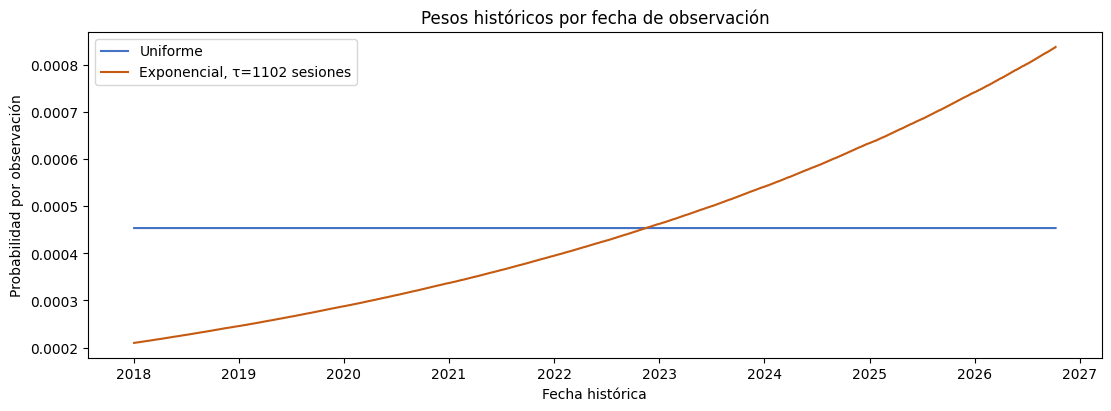

In [8]:
import matplotlib.pyplot as plt
fig, axis = plt.subplots(figsize=(11, 4), constrained_layout=True)
axis.plot(historical_dates, uniform_probabilities, label='Uniforme', color='#4472C4')
axis.plot(historical_dates, exponential_probabilities, label='Exponencial, τ=1102 sesiones', color='#C55A11')
axis.set_title('Pesos históricos por fecha de observación')
axis.set_xlabel('Fecha histórica')
axis.set_ylabel('Probabilidad por observación')
axis.legend(loc='best')
plt.show()


## Interpretación

Con $\tau=1{,}102$, la distribución exponencial asignó 0.051802 de masa a las últimas 63 observaciones, 0.195442 a las últimas 252 y 0.666667 a las últimas 1,102; bajo pesos uniformes esas masas fueron 0.028584, 0.114338 y 0.500000. El tamaño efectivo por concentración pasó de 2,204.0 a 1,907.820. La observación más reciente recibió aproximadamente cuatro veces el peso de la más antigua; las observaciones antiguas no se eliminan, pierden peso relativo, mientras que las recientes lo ganan. $N_{eff}$ no estima cuántas observaciones son temporalmente independientes.

Para SPY, la media/desviación estándar logarítmica ponderada uniforme fue 0.000543/0.011978 y la exponencial 0.000594/0.011348. Para TLT fue -0.000100/0.009638 frente a -0.000161/0.009409; para GLD, 0.000509/0.010789 frente a 0.000593/0.011872. Una media ponderada mayor no es evidencia de mayor retorno futuro.

Esta elección favorece recencia, pero no identifica automáticamente estados económicos. Incluso si estos mismos pesos se usaran en todos los pasos de un remuestreo, los pasos seguirían siendo independientes: cambiar la distribución de origen no modela dependencia temporal ni demuestra mejora predictiva.

No se generan nuevas simulaciones ni se implementan estados, FFR, Entropy Pooling, carteras, optimización ni backtest.

# 5. Trayectorias con ponderación temporal

Este bloque compara dos experimentos nuevos H=5: uno con pesos uniformes y otro con los pesos exponenciales ya construidos. Comparten números aleatorios uniformes para acoplar la comparación. Eso no implica dependencia temporal entre pasos dentro de cada modelo, ni convierte la ponderación exponencial en una mejora predictiva demostrada.

In [9]:
COMPARISON_S, COMPARISON_H, COMPARISON_SEED = 10_000, 5, 20_261_009
COMPARISON_ABSOLUTE_TOLERANCE, COMPARISON_RELATIVE_TOLERANCE = 1e-12, 1e-10
COMPARISON_RNG_NAME = 'NumPy Generator(PCG64)'
comparison_rng = np.random.Generator(np.random.PCG64(COMPARISON_SEED))
comparison_uniforms = comparison_rng.random((COMPARISON_S, COMPARISON_H))

def cdf_for_sampling(probabilities):
    cdf = np.cumsum(probabilities)
    prior_last_value = float(cdf[-1])
    cdf[-1] = 1.0  # Numerical endpoint only; probabilities themselves remain unchanged.
    return cdf, float(1.0 - prior_last_value)

comparison_cdfs, comparison_cdf_adjustments = {}, {}
for scheme, probabilities in {'Uniform': uniform_probabilities, 'Exponential, tau=1102': exponential_probabilities}.items():
    comparison_cdfs[scheme], comparison_cdf_adjustments[scheme] = cdf_for_sampling(probabilities)

# side='right': choose the smallest index whose CDF is strictly greater than u.
comparison_uniforms_by_scheme = {scheme: comparison_uniforms for scheme in comparison_cdfs}
comparison_indices = {scheme: np.searchsorted(cdf, comparison_uniforms_by_scheme[scheme], side='right') for scheme, cdf in comparison_cdfs.items()}
comparison_log_daily = {scheme: log_return_values[indices, :] for scheme, indices in comparison_indices.items()}
comparison_simple_daily = {scheme: np.expm1(values) for scheme, values in comparison_log_daily.items()}
comparison_log_cumulative = {scheme: np.cumsum(values, axis=1) for scheme, values in comparison_log_daily.items()}
comparison_simple_cumulative = {scheme: np.expm1(values) for scheme, values in comparison_log_cumulative.items()}
comparison_terminal_log = {scheme: values[:, -1, :] for scheme, values in comparison_log_cumulative.items()}
comparison_terminal_simple = {scheme: values[:, -1, :] for scheme, values in comparison_simple_cumulative.items()}
comparison_mc_weights = np.full(COMPARISON_S, 1.0 / COMPARISON_S)
comparison_frequencies = {scheme: np.bincount(indices.ravel(), minlength=T) for scheme, indices in comparison_indices.items()}
comparison_replay_rng = np.random.Generator(np.random.PCG64(COMPARISON_SEED))
comparison_replay_uniforms = comparison_replay_rng.random((COMPARISON_S, COMPARISON_H))

def composition_error(log_cumulative, simple_daily):
    reference = np.cumprod(1.0 + simple_daily, axis=1) - 1.0
    absolute = np.abs(np.expm1(log_cumulative) - reference)
    materially_nonzero = np.abs(reference) > COMPARISON_ABSOLUTE_TOLERANCE
    relative = np.zeros_like(absolute); relative[materially_nonzero] = absolute[materially_nonzero] / np.abs(reference[materially_nonzero])
    return float(absolute.max()), float(relative[materially_nonzero].max()) if materially_nonzero.any() else 0.0, bool(np.all(absolute <= COMPARISON_ABSOLUTE_TOLERANCE + COMPARISON_RELATIVE_TOLERANCE * np.abs(reference)))

comparison_composition = {scheme: composition_error(comparison_log_cumulative[scheme], comparison_simple_daily[scheme]) for scheme in comparison_indices}
comparison_checks = {
    'U tiene S × H y dominio [0, 1)': comparison_uniforms.shape == (COMPARISON_S, COMPARISON_H) and bool(np.isfinite(comparison_uniforms).all() and (comparison_uniforms >= 0).all() and (comparison_uniforms < 1).all()),
    'Ambos esquemas usan exactamente la misma U': all(np.array_equal(values, comparison_uniforms) for values in comparison_uniforms_by_scheme.values()),
    'CDF no decrecientes y último valor uno': all(np.all(np.diff(cdf) >= 0) and cdf[-1] == 1.0 for cdf in comparison_cdfs.values()),
    'Índices válidos y filas completas seleccionadas': all(indices.shape == (COMPARISON_S, COMPARISON_H) and bool(((indices >= 0) & (indices < T)).all()) and np.array_equal(comparison_log_daily[scheme], log_return_values[indices, :]) for scheme, indices in comparison_indices.items()),
    'Orden de símbolos conservado': tuple(return_symbols) == tuple(eligible_symbols) and N == 125,
    'Retornos finitos y dentro del dominio': all(np.isfinite(comparison_log_daily[scheme]).all() and np.isfinite(comparison_terminal_simple[scheme]).all() and (comparison_simple_daily[scheme] > -1).all() and (comparison_terminal_simple[scheme] > -1).all() for scheme in comparison_indices),
    'Composición logarítmica concilia con producto simple': all(result[2] for result in comparison_composition.values()),
    'Generador nuevo reproduce U': bool(np.array_equal(comparison_uniforms, comparison_replay_uniforms)),
    'Frecuencias suman S × H en ambos esquemas': all(int(frequencies.sum()) == COMPARISON_S * COMPARISON_H for frequencies in comparison_frequencies.values()),
    'Pesos Monte Carlo suman uno': bool((comparison_mc_weights > 0).all() and np.isclose(comparison_mc_weights.sum(), 1.0, atol=COMPARISON_ABSOLUTE_TOLERANCE)),
    'Experimentos anteriores permanecen intactos': bool(np.array_equal(selected_log_returns, log_return_values[selected_indices]) and np.array_equal(multi_session_daily_log_returns, log_return_values[multi_session_indices]) and np.array_equal(historical_probabilities, np.full(T, 1.0 / T))),
}
comparison_rows, comparison_quantile_checks = [], []
for scheme, probabilities in {'Uniform': uniform_probabilities, 'Exponential, tau=1102': exponential_probabilities}.items():
    terminal_log, terminal_simple = comparison_terminal_log[scheme], comparison_terminal_simple[scheme]
    log_mean = np.mean(terminal_log, axis=0); log_std = np.std(terminal_log, axis=0, ddof=0)
    simple_mean = np.mean(terminal_simple, axis=0); simple_std = np.std(terminal_simple, axis=0, ddof=0)
    ordered = np.sort(terminal_simple, axis=0); q = ordered[np.ceil(np.array([.05, .50, .95]) * COMPARISON_S).astype(int)-1]
    comparison_quantile_checks.append(bool(np.all(np.diff(q, axis=0) >= 0) and all(np.all(np.any(ordered == q[level][None, :], axis=0)) for level in range(3))))
    source_mean, source_std = weighted_log_moments(probabilities)
    for index, symbol in enumerate(return_symbols): comparison_rows.append({'scheme': scheme, 'symbol': symbol, 'observations': COMPARISON_S, 'simulated_log_mean': float(log_mean[index]), 'analytic_log_mean_h': float(COMPARISON_H * source_mean[index]), 'log_mean_difference': float(log_mean[index] - COMPARISON_H * source_mean[index]), 'simulated_log_std': float(log_std[index]), 'analytic_log_std_sqrt_h': float(np.sqrt(COMPARISON_H) * source_std[index]), 'log_std_difference': float(log_std[index] - np.sqrt(COMPARISON_H) * source_std[index]), 'simple_mean': float(simple_mean[index]), 'simple_std': float(simple_std[index]), 'q05': float(q[0,index]), 'q50': float(q[1,index]), 'q95': float(q[2,index])})
comparison_summary = pl.DataFrame(comparison_rows).sort(['scheme', 'symbol'])
comparison_example_summary = comparison_summary.filter(pl.col('symbol').is_in(EXPOSURE_EXAMPLES)).with_columns(pl.col('symbol').replace_strict({symbol: index for index, symbol in enumerate(EXPOSURE_EXAMPLES)}).alias('_order')).sort(['_order', 'scheme']).drop('_order')
comparison_checks['Cuantiles terminales ordenados y observados'] = all(comparison_quantile_checks)
if not all(comparison_checks.values()): raise AssertionError([key for key, value in comparison_checks.items() if not value])
comparison_check_summary = pl.DataFrame({'check': list(comparison_checks), 'result': ['PASS' if value else 'FAIL' for value in comparison_checks.values()]})
comparison_cdf_adjustment_summary = pl.DataFrame({'scheme': list(comparison_cdf_adjustments), 'last_cdf_adjustment_to_one': list(comparison_cdf_adjustments.values())})
comparison_error_summary = pl.DataFrame({'scheme': list(comparison_composition), 'max_composition_absolute_error': [value[0] for value in comparison_composition.values()], 'max_composition_relative_error_reference_above_absolute_tolerance': [value[1] for value in comparison_composition.values()]})
from IPython.display import display
display(comparison_cdf_adjustment_summary); display(comparison_example_summary)
comparison_error_summary, comparison_check_summary


scheme,last_cdf_adjustment_to_one
str,f64
"""Uniform""",4.0856e-14
"""Exponential, tau=1102""",-2.2204e-16


scheme,symbol,observations,simulated_log_mean,analytic_log_mean_h,log_mean_difference,simulated_log_std,analytic_log_std_sqrt_h,log_std_difference,simple_mean,simple_std,q05,q50,q95
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Exponential, tau=1102""","""SPY""",10000,0.003177,0.00297,0.000207,0.025866,0.025376,0.00049,0.003517,0.025897,-0.037409,0.003782,0.042221
"""Uniform""","""SPY""",10000,0.002471,0.002716,-0.000245,0.026821,0.026783,0.000038,0.002833,0.026819,-0.040278,0.003576,0.042485
"""Exponential, tau=1102""","""TLT""",10000,-0.000571,-0.000804,0.000233,0.021784,0.02104,0.000745,-0.000334,0.021797,-0.034748,-0.000767,0.035398
"""Uniform""","""TLT""",10000,-0.000674,-0.0005,-0.000174,0.021569,0.021552,0.000017,-0.000441,0.021554,-0.034842,-0.000389,0.034595
"""Exponential, tau=1102""","""GLD""",10000,0.002895,0.002964,-0.00007,0.026642,0.026547,0.000095,0.003254,0.026594,-0.04033,0.003806,0.045057
"""Uniform""","""GLD""",10000,0.00273,0.002547,0.000183,0.024329,0.024126,0.000203,0.003029,0.024276,-0.03652,0.003622,0.041337


(shape: (2, 3)
 ┌───────────────────────┬────────────────────────────────┬─────────────────────────────────┐
 │ scheme                ┆ max_composition_absolute_error ┆ max_composition_relative_error… │
 │ ---                   ┆ ---                            ┆ ---                             │
 │ str                   ┆ f64                            ┆ f64                             │
 ╞═══════════════════════╪════════════════════════════════╪═════════════════════════════════╡
 │ Uniform               ┆ 8.8818e-16                     ┆ 0.000017                        │
 │ Exponential, tau=1102 ┆ 8.8818e-16                     ┆ 0.000008                        │
 └───────────────────────┴────────────────────────────────┴─────────────────────────────────┘,
 shape: (12, 2)
 ┌─────────────────────────────────┬────────┐
 │ check                           ┆ result │
 │ ---                             ┆ ---    │
 │ str                             ┆ str    │
 ╞══════════════════════════════

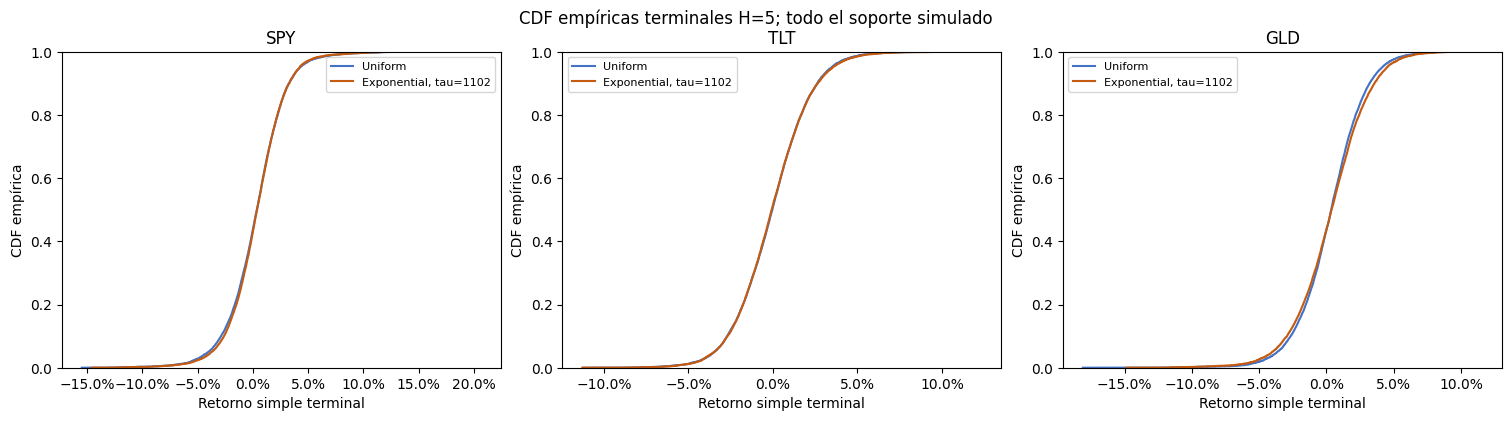

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), constrained_layout=True)
for axis, symbol, index in zip(axes, EXPOSURE_EXAMPLES, example_indices):
    for scheme, color in [('Uniform', '#4472C4'), ('Exponential, tau=1102', '#C55A11')]:
        values = np.sort(comparison_terminal_simple[scheme][:, index]); axis.step(values, np.arange(1, COMPARISON_S + 1) / COMPARISON_S, where='post', label=scheme, color=color)
    axis.set_title(symbol); axis.set_xlabel('Retorno simple terminal'); axis.set_ylabel('CDF empírica'); axis.set_ylim(0, 1); axis.xaxis.set_major_formatter(PercentFormatter(1)); axis.legend(fontsize=8)
fig.suptitle('CDF empíricas terminales H=5; todo el soporte simulado', y=1.04); plt.show()


## Interpretación y límites

Con estas 10,000 trayectorias a cinco sesiones, la ponderación exponencial cambió los resultados descriptivos respecto del remuestreo uniforme. Por ejemplo, para SPY la media simple simulada fue 0.3517% con ponderación exponencial frente a 0.2833% con pesos uniformes; su desviación simple fue 2.5897% frente a 2.6819%, y los cuantiles 5%/50%/95% fueron -3.7409%/0.3782%/4.2221% frente a -4.0278%/0.3576%/4.2485%. Para TLT, las medias fueron -0.0334% y -0.0441%; para GLD, 0.3254% y 0.3029%, respectivamente. Estas diferencias proceden de reponderar observaciones históricas, no de evidencia de mejora predictiva.

Ambos modelos mantienen pasos independientes y los pesos exponenciales permanecen fijos durante los cinco pasos: no hay actualización de estado ni pesos dependientes de la trayectoria. Los números aleatorios comunes ayudan a comparar los dos experimentos, pero no eliminan el error Monte Carlo ni garantizan reducirlo para cualquier estadística. La semivida no fue elegida mediante validación predictiva. Cruces o desplazamientos de las CDF no son recomendaciones de inversión.

No se implementan estados, FFR, Entropy Pooling, carteras, optimización ni backtest.

# 6. Referencias económicas exactas y cierre

Este bloque reutiliza, sin generar sorteos nuevos, las trayectorias comparativas del bloque 5. Separa el efecto exacto de cambiar las probabilidades históricas del error Monte Carlo de una simulación finita.

Para cada instrumento, el factor bruto diario es $G_t=1+r_t=\exp(\ell_t)$. Bajo sorteos independientes con probabilidades fijas durante $H$ sesiones, $a=\sum_t p_tG_t$ y $b=\sum_t p_tG_t^2$ producen $E[R_H]=a^H-1$ y $\mathrm{Var}(R_H)=b^H-a^{2H}$. El factor bruto acumulado es el producto de factores diarios independientes. Estas son propiedades exactas del modelo especificado; no son afirmaciones sobre el mercado.

In [11]:
ANALYTIC_VARIANCE_TOLERANCE = 1e-13
PAIRED_DIFFERENCE_TOLERANCE = 1e-14

gross_daily_factors = np.exp(log_return_values)
if not (np.isfinite(gross_daily_factors).all() and (gross_daily_factors > 0).all()):
    raise AssertionError('Los factores brutos diarios deben ser positivos y finitos.')

def exact_simple_terminal_reference(probabilities, horizon):
    a = probabilities @ gross_daily_factors
    b = probabilities @ np.square(gross_daily_factors)
    a_h = np.exp(horizon * np.log(a))
    b_h = np.exp(horizon * np.log(b))
    raw_variance = b_h - np.square(a_h)
    scale = np.maximum(1.0, np.maximum(np.abs(b_h), np.abs(np.square(a_h))))
    rounding_negative = (raw_variance < 0) & (raw_variance >= -ANALYTIC_VARIANCE_TOLERANCE * scale)
    material_negative = raw_variance < -ANALYTIC_VARIANCE_TOLERANCE * scale
    if material_negative.any():
        raise AssertionError(f'Varianza analítica materialmente negativa: {np.flatnonzero(material_negative).tolist()}')
    variance = raw_variance.copy()
    variance[rounding_negative] = 0.0  # Explicit treatment of round-off only.
    return {'a': a, 'b': b, 'mean': a_h - 1.0, 'variance': variance, 'std': np.sqrt(variance), 'rounding_negative_count': int(rounding_negative.sum()), 'min_raw_variance': float(raw_variance.min())}

comparison_probability_schemes = {'Uniform': uniform_probabilities, 'Exponential, tau=1102': exponential_probabilities}
analytic_references = {scheme: exact_simple_terminal_reference(probabilities, COMPARISON_H) for scheme, probabilities in comparison_probability_schemes.items()}

economic_rows = []
for scheme, reference in analytic_references.items():
    simulated = comparison_terminal_simple[scheme]
    simulated_mean = np.average(simulated, axis=0, weights=comparison_mc_weights)
    simulated_std = np.sqrt(np.average(np.square(simulated - simulated_mean), axis=0, weights=comparison_mc_weights))
    standard_error = np.sqrt(reference['variance'] / COMPARISON_S)
    for index, symbol in enumerate(return_symbols):
        economic_rows.append({'scheme': scheme, 'symbol': symbol, 'analytic_simple_mean': float(reference['mean'][index]), 'simulated_simple_mean': float(simulated_mean[index]), 'simulation_minus_analytic_mean': float(simulated_mean[index] - reference['mean'][index]), 'mc_standard_error_mean': float(standard_error[index]), 'analytic_simple_std': float(reference['std'][index]), 'simulated_simple_std': float(simulated_std[index])})
economic_reference_summary = pl.DataFrame(economic_rows).sort(['scheme', 'symbol'])
economic_examples = economic_reference_summary.filter(pl.col('symbol').is_in(EXPOSURE_EXAMPLES)).with_columns(pl.col('symbol').replace_strict({symbol: index for index, symbol in enumerate(EXPOSURE_EXAMPLES)}).alias('_order')).sort(['_order', 'scheme']).drop('_order')

paired_terminal_difference = comparison_terminal_simple['Exponential, tau=1102'] - comparison_terminal_simple['Uniform']
paired_rows = []
for index, symbol in enumerate(return_symbols):
    d = paired_terminal_difference[:, index]
    simulated_difference = float(d.mean())
    exact_difference = float(analytic_references['Exponential, tau=1102']['mean'][index] - analytic_references['Uniform']['mean'][index])
    paired_se = float(d.std(ddof=1) / np.sqrt(COMPARISON_S))
    paired_rows.append({'symbol': symbol, 'exact_exponential_minus_uniform_mean': exact_difference, 'paired_simulated_mean_difference': simulated_difference, 'simulation_minus_exact_difference': simulated_difference - exact_difference, 'paired_mc_standard_error_ddof_1': paired_se})
paired_effect_summary = pl.DataFrame(paired_rows).sort('symbol')
paired_examples = paired_effect_summary.filter(pl.col('symbol').is_in(EXPOSURE_EXAMPLES)).with_columns(pl.col('symbol').replace_strict({symbol: index for index, symbol in enumerate(EXPOSURE_EXAMPLES)}).alias('_order')).sort('_order').drop('_order')

economic_checks = {
    'Factores brutos positivos y finitos': bool(np.isfinite(gross_daily_factors).all() and (gross_daily_factors > 0).all()),
    'Dimensiones y símbolos conservados': gross_daily_factors.shape == (T, N) and tuple(return_symbols) == tuple(eligible_symbols),
    'Referencias analíticas finitas y varianzas no negativas': all(np.isfinite(reference['mean']).all() and np.isfinite(reference['variance']).all() and np.isfinite(reference['std']).all() and (reference['variance'] >= 0).all() for reference in analytic_references.values()),
    'Media de D concilia con diferencia de medias simuladas': bool(np.allclose(paired_terminal_difference.mean(axis=0), comparison_terminal_simple['Exponential, tau=1102'].mean(axis=0) - comparison_terminal_simple['Uniform'].mean(axis=0), atol=PAIRED_DIFFERENCE_TOLERANCE, rtol=0)),
    'Simulaciones y probabilidades previas intactas': bool(np.array_equal(comparison_log_daily['Uniform'], log_return_values[comparison_indices['Uniform'], :]) and np.array_equal(comparison_log_daily['Exponential, tau=1102'], log_return_values[comparison_indices['Exponential, tau=1102'], :]) and np.array_equal(uniform_probabilities, np.full(T, 1.0 / T)) and np.array_equal(historical_probabilities, uniform_probabilities)),
}
if not all(economic_checks.values()):
    raise AssertionError([name for name, passed in economic_checks.items() if not passed])

variance_rounding_summary = pl.DataFrame({
    'scheme': list(analytic_references),
    'rounding_negative_variance_count': [reference['rounding_negative_count'] for reference in analytic_references.values()],
    'minimum_raw_variance': [reference['min_raw_variance'] for reference in analytic_references.values()],
})
economic_check_summary = pl.DataFrame({'check': list(economic_checks), 'result': ['PASS' if value else 'FAIL' for value in economic_checks.values()]})
from IPython.display import display
display(economic_examples)
display(paired_examples)
variance_rounding_summary, economic_check_summary


scheme,symbol,analytic_simple_mean,simulated_simple_mean,simulation_minus_analytic_mean,mc_standard_error_mean,analytic_simple_std,simulated_simple_std
str,str,f64,f64,f64,f64,f64,f64
"""Exponential, tau=1102""","""SPY""",0.003297,0.003517,0.00022,0.000254,0.025428,0.025897
"""Uniform""","""SPY""",0.003078,0.002833,-0.000245,0.000268,0.026794,0.026819
"""Exponential, tau=1102""","""TLT""",-0.000583,-0.000334,0.000249,0.00021,0.021036,0.021797
"""Uniform""","""TLT""",-0.000267,-0.000441,-0.000174,0.000216,0.021559,0.021554
"""Exponential, tau=1102""","""GLD""",0.003321,0.003254,-0.000067,0.000265,0.026514,0.026594
"""Uniform""","""GLD""",0.002841,0.003029,0.000188,0.000241,0.024107,0.024276


symbol,exact_exponential_minus_uniform_mean,paired_simulated_mean_difference,simulation_minus_exact_difference,paired_mc_standard_error_ddof_1
str,f64,f64,f64,f64
"""SPY""",0.000219,0.000683,0.000464,0.000374
"""TLT""",-0.000315,0.000107,0.000423,0.000304
"""GLD""",0.00048,0.000224,-0.000256,0.00036


(shape: (2, 3)
 ┌───────────────────────┬─────────────────────────────────┬──────────────────────┐
 │ scheme                ┆ rounding_negative_variance_cou… ┆ minimum_raw_variance │
 │ ---                   ┆ ---                             ┆ ---                  │
 │ str                   ┆ i64                             ┆ f64                  │
 ╞═══════════════════════╪═════════════════════════════════╪══════════════════════╡
 │ Uniform               ┆ 0                               ┆ 1.1602e-7            │
 │ Exponential, tau=1102 ┆ 0                               ┆ 1.1968e-7            │
 └───────────────────────┴─────────────────────────────────┴──────────────────────┘,
 shape: (5, 2)
 ┌─────────────────────────────────┬────────┐
 │ check                           ┆ result │
 │ ---                             ┆ ---    │
 │ str                             ┆ str    │
 ╞═════════════════════════════════╪════════╡
 │ Factores brutos positivos y fi… ┆ PASS   │
 │ Dimensiones y símb

# Cierre de la notebook 03

La notebook construyó un remuestreo conjunto de una sesión y su composición independiente a cinco sesiones. Después mostró cómo la ponderación temporal concentra la masa en observaciones recientes y distinguió dos niveles: propiedades exactas del modelo fijado —incluidas las referencias económicas de factores brutos— y el error Monte Carlo de las 10,000 trayectorias.

En particular, para TLT la diferencia exacta de media simple exponencial menos uniforme fue -0.0315% a cinco sesiones. En esta simulación emparejada fue +0.0107%, una diferencia simulación-menos-referencia de +0.0423%, frente a un error estándar Monte Carlo emparejado de 0.0304%. Por ello, este resultado de la simulación no permite presentar la ponderación exponencial como una mejora: la referencia exacta del modelo y el error Monte Carlo deben mantenerse separados.

Ambos modelos mantienen independencia entre pasos y ninguno actualiza las probabilidades según el estado de la trayectoria. Por tanto, los supuestos de representatividad histórica, independencia temporal y la semivida elegida siguen pendientes de validación predictiva. No se ha implementado un FFR completo.

El siguiente desarrollo abordará condicionamiento por estado en una notebook separada; su alcance se definirá después.